In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [13]:

from pathlib import Path


DATA = Path("../data/raw")

train = pd.read_csv(DATA / "cs-training.csv")

test = pd.read_csv(DATA / "cs-test.csv")


dictionary = pd.read_excel(DATA / "dataDictionary.xls")

dictionary

,Unnamed: 0,Unnamed: 1,Unnamed: 2
0,Variable Name,Description,Type
1,SeriousDlqin2yrs,Person experienced 90 days past due delinquenc...,Y/N
2,RevolvingUtilizationOfUnsecuredLines,Total balance on credit cards and personal lin...,percentage
3,age,Age of borrower in years,integer
4,NumberOfTime30-59DaysPastDueNotWorse,Number of times borrower has been 30-59 days p...,integer
5,DebtRatio,"Monthly debt payments, alimony,living costs di...",percentage
6,MonthlyIncome,Monthly income,real
7,NumberOfOpenCreditLinesAndLoans,Number of Open loans (installment like car loa...,integer
8,NumberOfTimes90DaysLate,Number of times borrower has been 90 days or m...,integer
9,NumberRealEstateLoansOrLines,Number of mortgage and real estate loans inclu...,integer


In [15]:
def clean_index(df):
    return df.loc[:, ~df.columns.astype(str).str.startswith("Unnamed:")]

train = clean_index(train)
test = clean_index(test)

for name, df in [
    ("TRAINING DATA", train),
    ("TEST DATA", test),
    ("DATA DICTIONARY", dictionary),
]:
    print(f"\n{'=' * 50}")
    print(name)
    print("=" * 50)
    print("Shape:", df.shape)
    print("Columns:", df.columns.tolist())



TRAINING DATA
Shape: (150000, 11)
Columns: ['SeriousDlqin2yrs', 'RevolvingUtilizationOfUnsecuredLines', 'age', 'NumberOfTime30-59DaysPastDueNotWorse', 'DebtRatio', 'MonthlyIncome', 'NumberOfOpenCreditLinesAndLoans', 'NumberOfTimes90DaysLate', 'NumberRealEstateLoansOrLines', 'NumberOfTime60-89DaysPastDueNotWorse', 'NumberOfDependents']

TEST DATA
Shape: (101503, 11)
Columns: ['SeriousDlqin2yrs', 'RevolvingUtilizationOfUnsecuredLines', 'age', 'NumberOfTime30-59DaysPastDueNotWorse', 'DebtRatio', 'MonthlyIncome', 'NumberOfOpenCreditLinesAndLoans', 'NumberOfTimes90DaysLate', 'NumberRealEstateLoansOrLines', 'NumberOfTime60-89DaysPastDueNotWorse', 'NumberOfDependents']

DATA DICTIONARY
Shape: (12, 3)
Columns: ['Unnamed: 0', 'Unnamed: 1', 'Unnamed: 2']


In [16]:
train.head()

,SeriousDlqin2yrs,RevolvingUtilizationOfUnsecuredLines,age,NumberOfTime30-59DaysPastDueNotWorse,DebtRatio,MonthlyIncome,NumberOfOpenCreditLinesAndLoans,NumberOfTimes90DaysLate,NumberRealEstateLoansOrLines,NumberOfTime60-89DaysPastDueNotWorse,NumberOfDependents
0,1,0.766127,45,2,0.802982,9120.0,13,0,6,0,2.0
1,0,0.957151,40,0,0.121876,2600.0,4,0,0,0,1.0
2,0,0.658180,38,1,0.085113,3042.0,2,1,0,0,0.0
3,0,0.233810,30,0,0.036050,3300.0,5,0,0,0,0.0
4,0,0.907239,49,1,0.024926,63588.0,7,0,1,0,0.0


In [17]:
test.head()

,SeriousDlqin2yrs,RevolvingUtilizationOfUnsecuredLines,age,NumberOfTime30-59DaysPastDueNotWorse,DebtRatio,MonthlyIncome,NumberOfOpenCreditLinesAndLoans,NumberOfTimes90DaysLate,NumberRealEstateLoansOrLines,NumberOfTime60-89DaysPastDueNotWorse,NumberOfDependents
0,NaN,0.885519,43,0,0.177513,5700.0,4,0,0,0,0.0
1,NaN,0.463295,57,0,0.527237,9141.0,15,0,4,0,2.0
2,NaN,0.043275,59,0,0.687648,5083.0,12,0,1,0,2.0
3,NaN,0.280308,38,1,0.925961,3200.0,7,0,2,0,0.0
4,NaN,1.000000,27,0,0.019917,3865.0,4,0,0,0,1.0


In [19]:
dictionary

,Unnamed: 0,Unnamed: 1,Unnamed: 2
0,Variable Name,Description,Type
1,SeriousDlqin2yrs,Person experienced 90 days past due delinquenc...,Y/N
2,RevolvingUtilizationOfUnsecuredLines,Total balance on credit cards and personal lin...,percentage
3,age,Age of borrower in years,integer
4,NumberOfTime30-59DaysPastDueNotWorse,Number of times borrower has been 30-59 days p...,integer
5,DebtRatio,"Monthly debt payments, alimony,living costs di...",percentage
6,MonthlyIncome,Monthly income,real
7,NumberOfOpenCreditLinesAndLoans,Number of Open loans (installment like car loa...,integer
8,NumberOfTimes90DaysLate,Number of times borrower has been 90 days or m...,integer
9,NumberRealEstateLoansOrLines,Number of mortgage and real estate loans inclu...,integer


In [20]:

# Target analysis
target = "SeriousDlqin2yrs"

print("\nTARGET DISTRIBUTION")
print(train[target].value_counts(dropna=False))

print("\nTARGET PERCENTAGES")
print((train[target].value_counts(normalize=True) * 100).round(2))



TARGET DISTRIBUTION
SeriousDlqin2yrs
0    139974
1     10026
Name: count, dtype: int64

TARGET PERCENTAGES
SeriousDlqin2yrs
0    93.32
1     6.68
Name: proportion, dtype: float64


In [23]:

print("\nMISSING VALUES — TRAINING DATA")
print(train.isnull().sum().sort_values(ascending=False))

print("\nMISSING VALUES — TEST DATA")
print(test.isnull().sum().sort_values(ascending=False))

print("\nTarget in test data:", target in test.columns)



MISSING VALUES — TRAINING DATA
MonthlyIncome                           29731
NumberOfDependents                       3924
SeriousDlqin2yrs                            0
age                                         0
RevolvingUtilizationOfUnsecuredLines        0
DebtRatio                                   0
NumberOfTime30-59DaysPastDueNotWorse        0
NumberOfOpenCreditLinesAndLoans             0
NumberOfTimes90DaysLate                     0
NumberRealEstateLoansOrLines                0
NumberOfTime60-89DaysPastDueNotWorse        0
dtype: int64

MISSING VALUES — TEST DATA
SeriousDlqin2yrs                        101503
MonthlyIncome                            20103
NumberOfDependents                        2626
age                                          0
RevolvingUtilizationOfUnsecuredLines         0
DebtRatio                                    0
NumberOfTime30-59DaysPastDueNotWorse         0
NumberOfOpenCreditLinesAndLoans              0
NumberOfTimes90DaysLate                      

In [24]:

print("\nMISSING VALUES — TRAINING DATA")
print(train.isnull().mean().sort_values(ascending=False)*100)

print("\nMISSING VALUES — TEST DATA")
print(test.isnull().mean().sort_values(ascending=False)*100)

print("\nTarget in test data:", target in test.columns)



MISSING VALUES — TRAINING DATA
MonthlyIncome                           19.820667
NumberOfDependents                       2.616000
SeriousDlqin2yrs                         0.000000
age                                      0.000000
RevolvingUtilizationOfUnsecuredLines     0.000000
DebtRatio                                0.000000
NumberOfTime30-59DaysPastDueNotWorse     0.000000
NumberOfOpenCreditLinesAndLoans          0.000000
NumberOfTimes90DaysLate                  0.000000
NumberRealEstateLoansOrLines             0.000000
NumberOfTime60-89DaysPastDueNotWorse     0.000000
dtype: float64

MISSING VALUES — TEST DATA
SeriousDlqin2yrs                        100.000000
MonthlyIncome                            19.805326
NumberOfDependents                        2.587116
age                                       0.000000
RevolvingUtilizationOfUnsecuredLines      0.000000
DebtRatio                                 0.000000
NumberOfTime30-59DaysPastDueNotWorse      0.000000
NumberOfOpenCredit

In [28]:

print("Exact duplicate rows:", train.duplicated().sum())

print("\nColumns that may be redundant identifiers:")
print([
    col for col in train.columns
    if "index" in col.lower() or col.lower() == "id"
])

print("\nUnique values per column:")
display(train.nunique().sort_values().to_frame("Unique Values"))


Exact duplicate rows: 609

Columns that may be redundant identifiers:
[]

Unique values per column:


,Unique Values
SeriousDlqin2yrs,2
NumberOfTime60-89DaysPastDueNotWorse,13
NumberOfDependents,13
NumberOfTime30-59DaysPastDueNotWorse,16
NumberOfTimes90DaysLate,19
NumberRealEstateLoansOrLines,28
NumberOfOpenCreditLinesAndLoans,58
age,86
MonthlyIncome,13594
DebtRatio,114194


In [29]:

print("Exact duplicate rows:", test.duplicated().sum())

print("\nColumns that may be redundant identifiers:")
print([
    col for col in test.columns
    if "index" in col.lower() or col.lower() == "id"
])

print("\nUnique values per column:")
display(test.nunique().sort_values().to_frame("Unique Values"))


Exact duplicate rows: 328

Columns that may be redundant identifiers:
[]

Unique values per column:


,Unique Values
SeriousDlqin2yrs,0
NumberOfTime60-89DaysPastDueNotWorse,12
NumberOfDependents,13
NumberOfTime30-59DaysPastDueNotWorse,16
NumberOfTimes90DaysLate,18
NumberRealEstateLoansOrLines,24
NumberOfOpenCreditLinesAndLoans,56
age,82
MonthlyIncome,11976
DebtRatio,79878


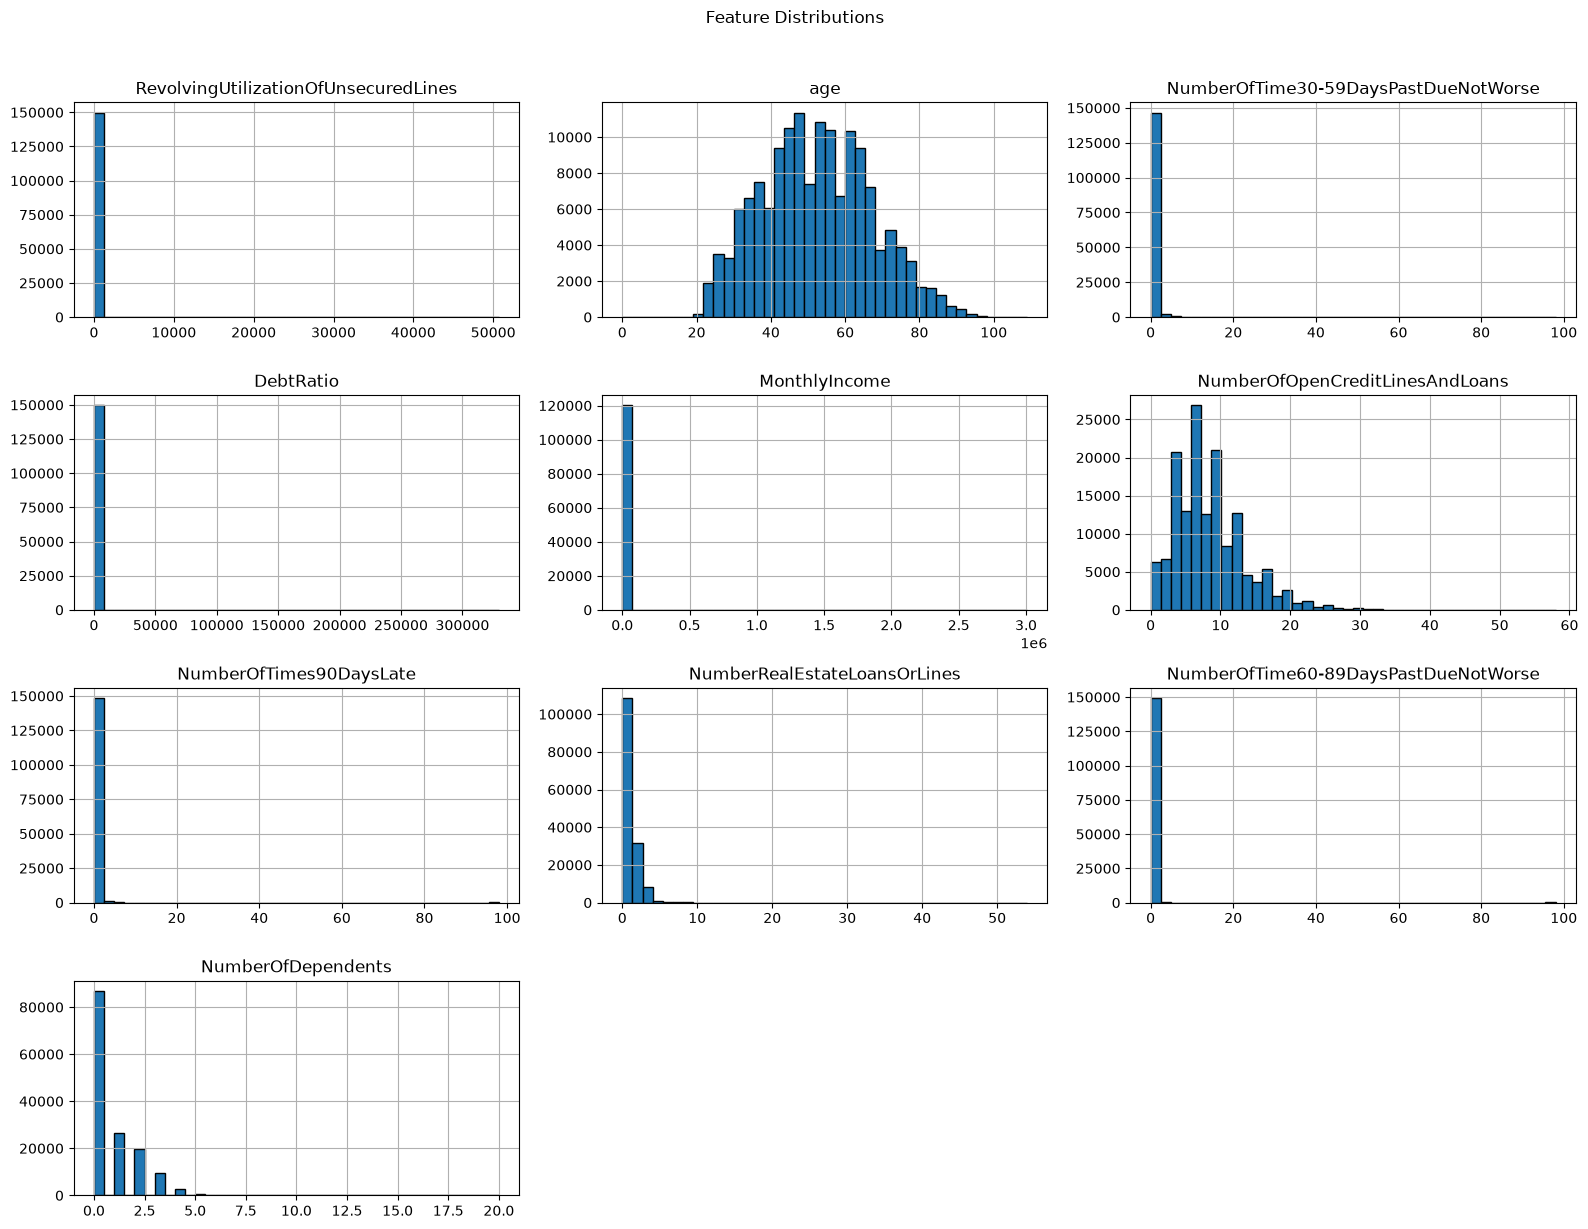

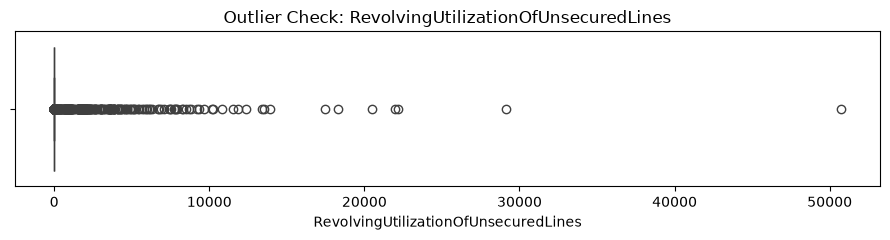

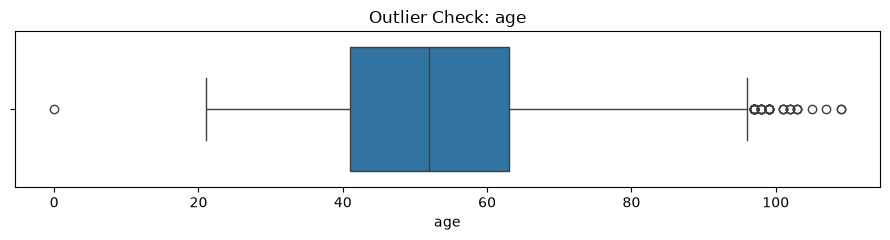

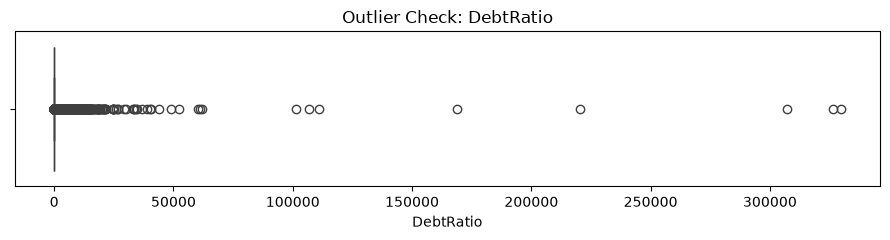

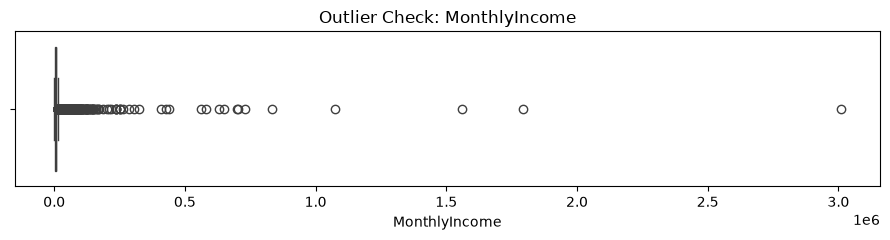

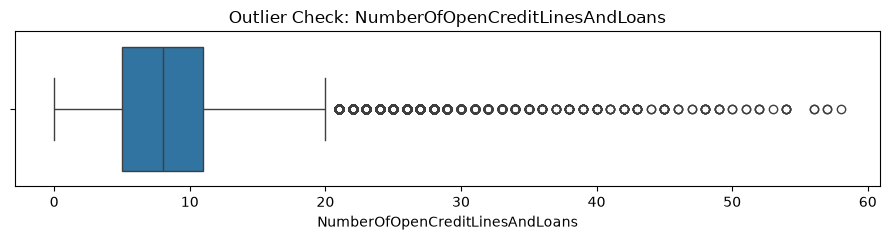

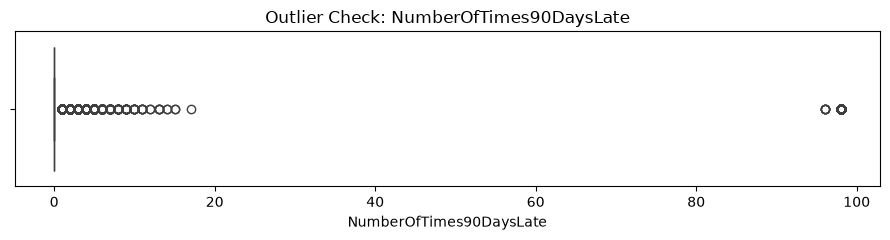

In [30]:

numeric_cols = train.select_dtypes(include=np.number).columns.drop(
    target, errors="ignore"
)

train[numeric_cols].hist(
    figsize=(16, 12),
    bins=40,
    edgecolor="black"
)
plt.suptitle("Feature Distributions", y=1.02)
plt.tight_layout()
plt.show()

selected = [
    "RevolvingUtilizationOfUnsecuredLines",
    "age",
    "DebtRatio",
    "MonthlyIncome",
    "NumberOfOpenCreditLinesAndLoans",
    "NumberOfTimes90DaysLate"
]

selected = [c for c in selected if c in train.columns]

for col in selected:
    plt.figure(figsize=(9, 2.5))
    sns.boxplot(x=train[col])
    plt.title(f"Outlier Check: {col}")
    plt.tight_layout()
    plt.show()


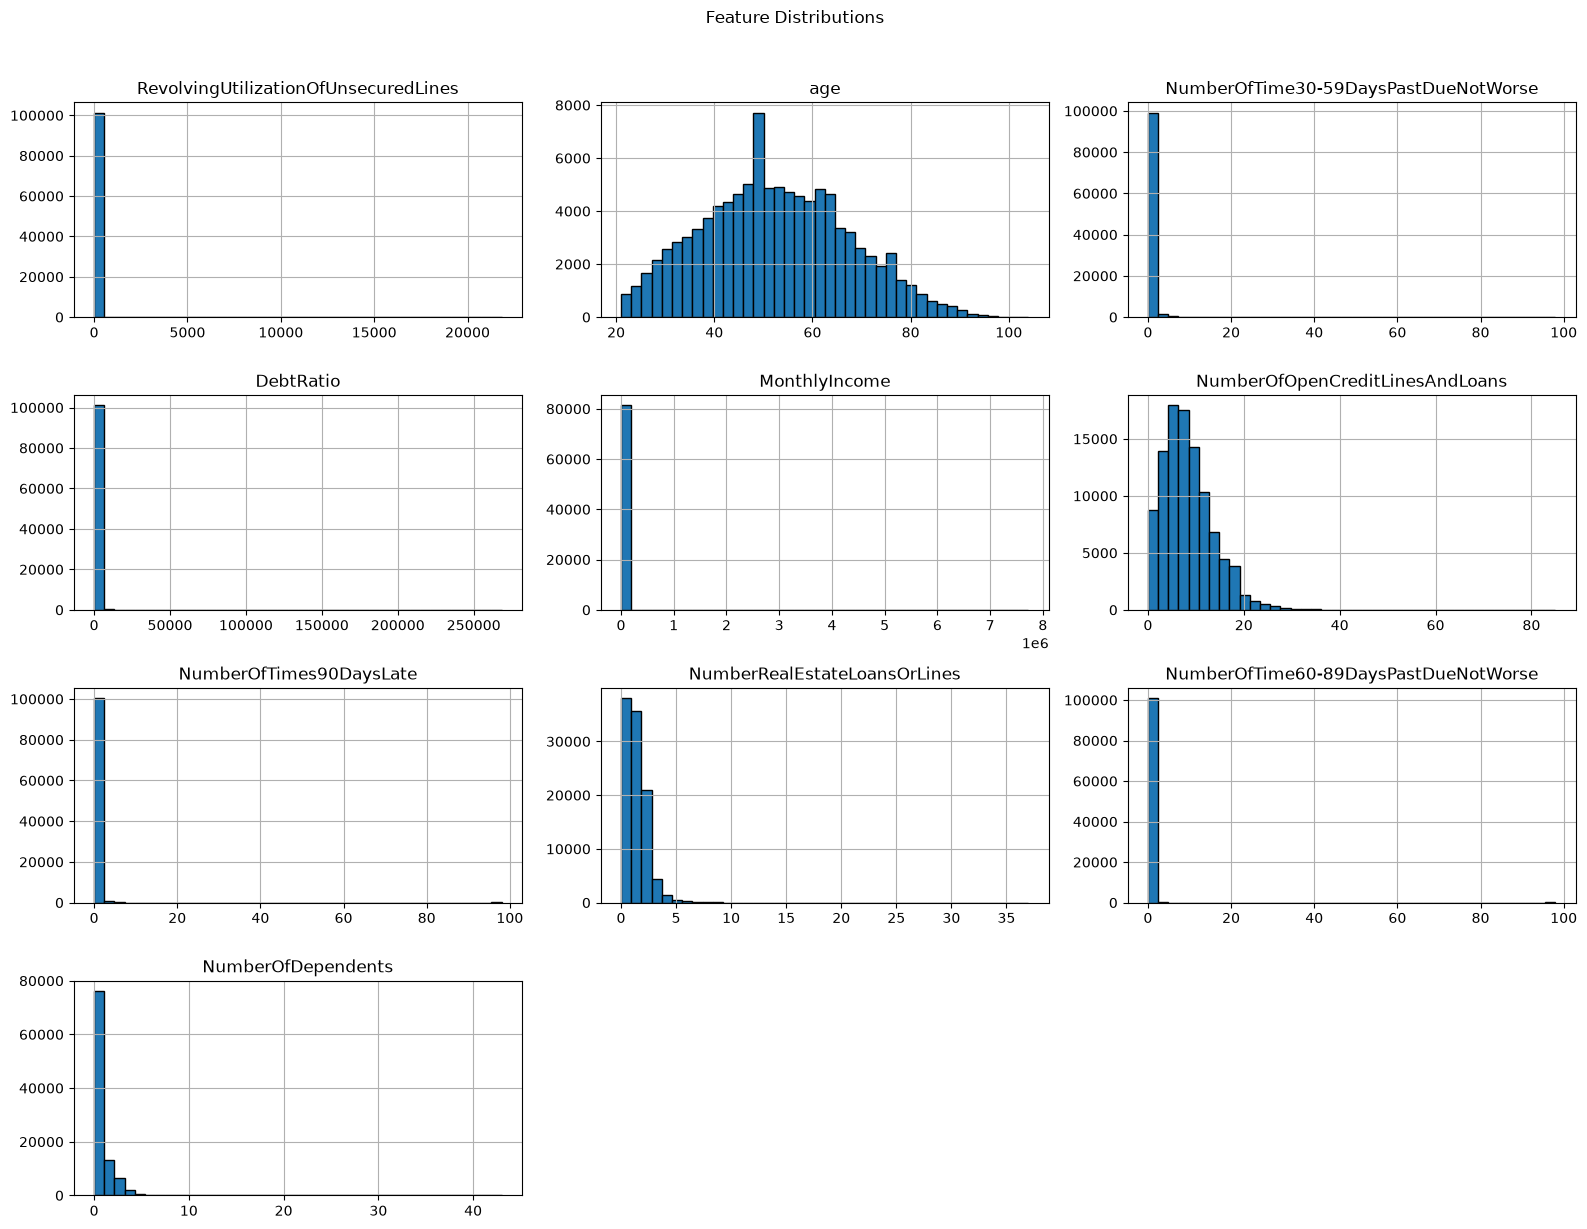

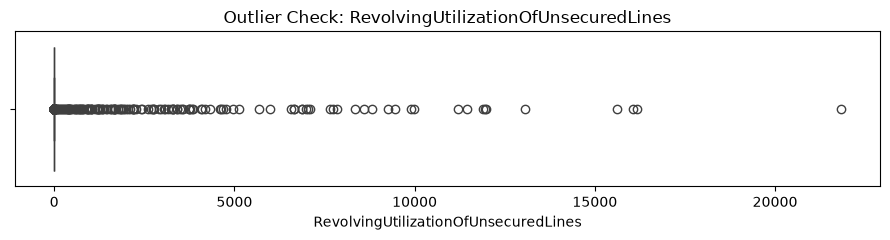

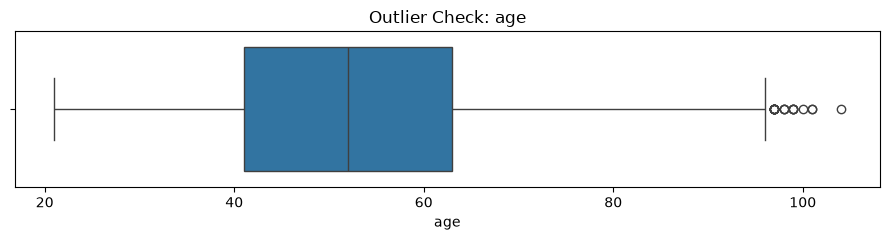

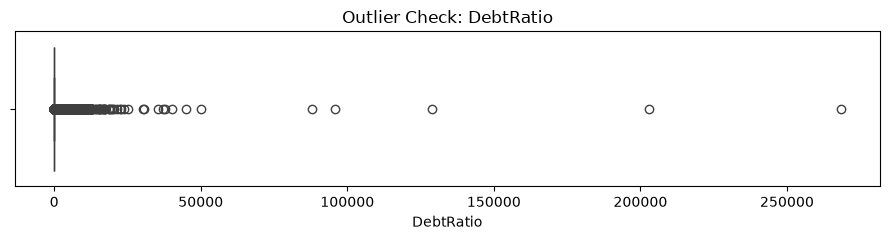

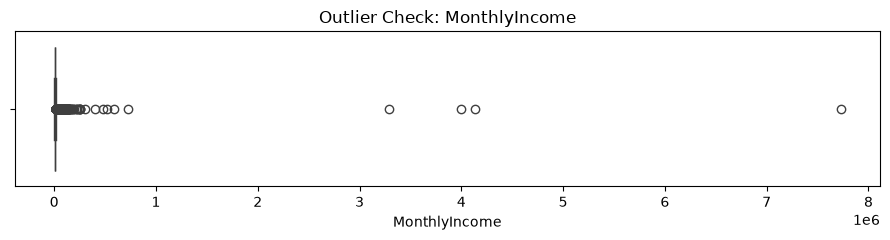

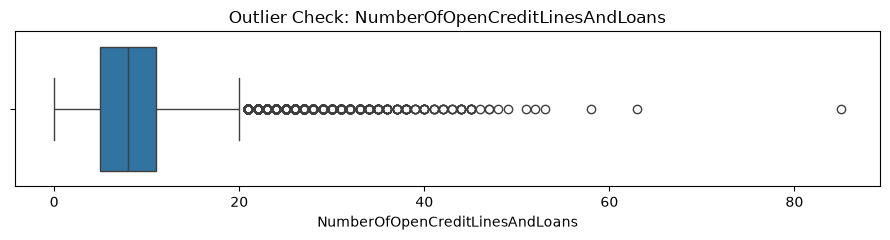

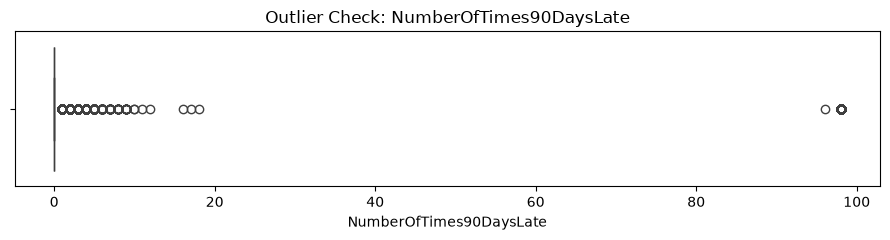

In [31]:

numeric_cols = test.select_dtypes(include=np.number).columns.drop(
    target, errors="ignore"
)

test[numeric_cols].hist(
    figsize=(16, 12),
    bins=40,
    edgecolor="black"
)
plt.suptitle("Feature Distributions", y=1.02)
plt.tight_layout()
plt.show()

selected = [
    "RevolvingUtilizationOfUnsecuredLines",
    "age",
    "DebtRatio",
    "MonthlyIncome",
    "NumberOfOpenCreditLinesAndLoans",
    "NumberOfTimes90DaysLate"
]

selected = [c for c in selected if c in test.columns]

for col in selected:
    plt.figure(figsize=(9, 2.5))
    sns.boxplot(x=test[col])
    plt.title(f"Outlier Check: {col}")
    plt.tight_layout()
    plt.show()


In [25]:
output = DATA.parent / "processed"
output.mkdir(parents=True, exist_ok=True)
train.to_csv(output / "training_clean_index.csv", index=False)

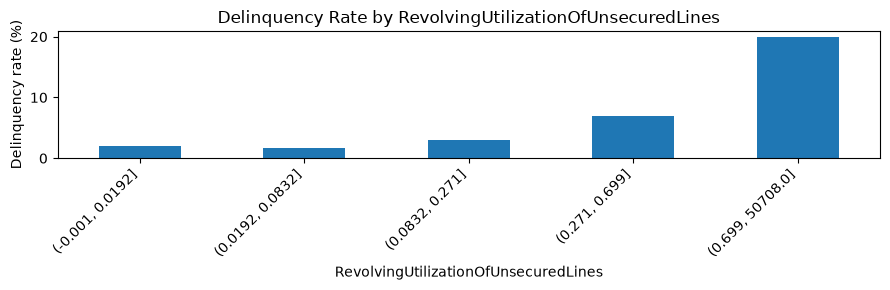

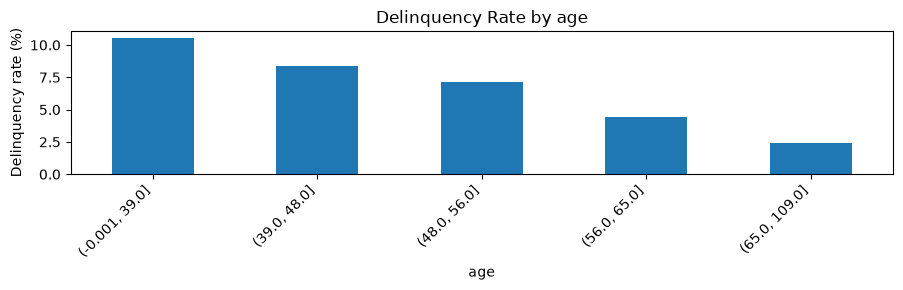

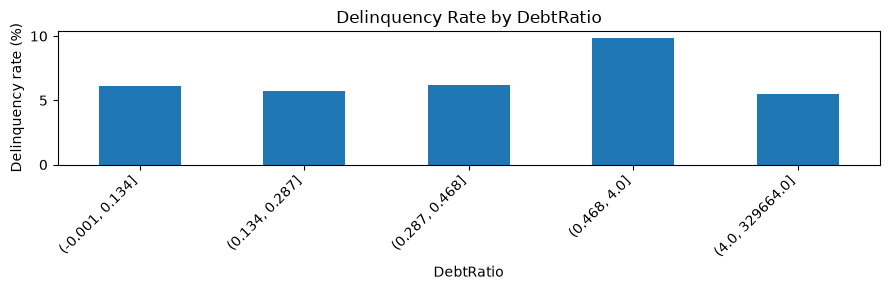

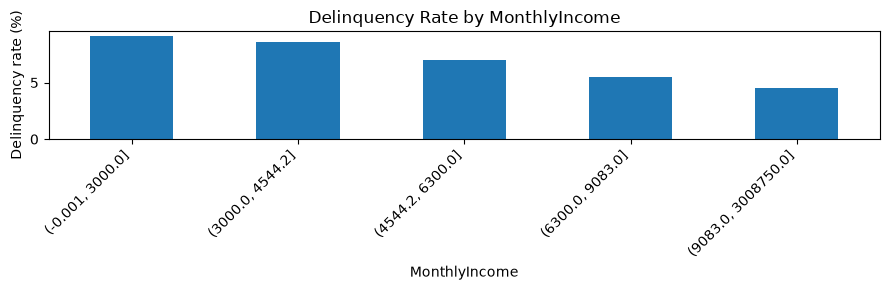

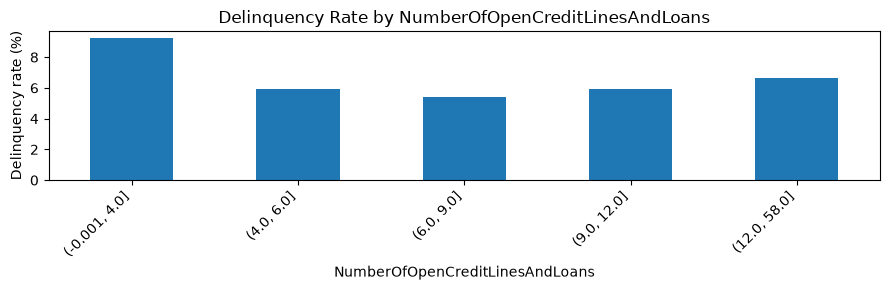

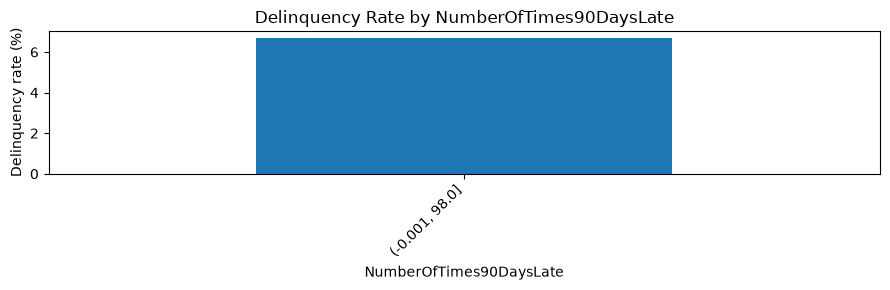

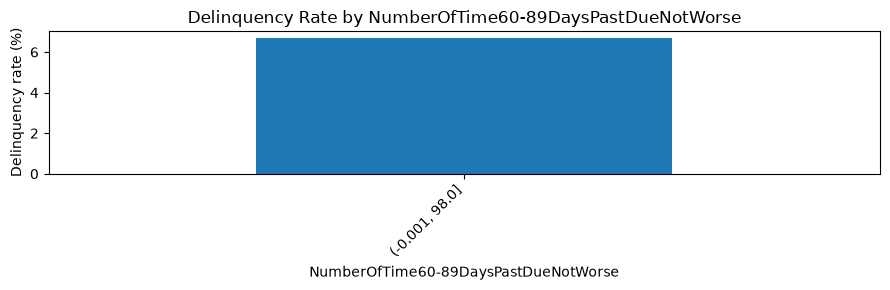

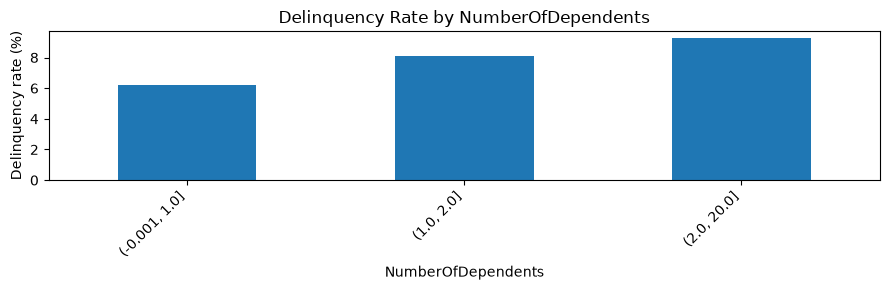

In [32]:

features = [
    "RevolvingUtilizationOfUnsecuredLines",
    "age",
    "DebtRatio",
    "MonthlyIncome",
    "NumberOfOpenCreditLinesAndLoans",
    "NumberOfTimes30-59DaysPastDueNotWorse",
    "NumberOfTimes90DaysLate",
    "NumberOfTime60-89DaysPastDueNotWorse",
    "NumberOfDependents"
]

features = [c for c in features if c in train.columns]

for col in features:
    temp = train[[col, target]].dropna()

    if temp[col].nunique() > 10:
        temp["Group"] = pd.qcut(
            temp[col], q=5, duplicates="drop"
        )
    else:
        temp["Group"] = temp[col]

    rates = temp.groupby(
        "Group", observed=True
    )[target].agg(["mean", "count"])

    rates["mean"] *= 100

    rates["mean"].plot(kind="bar", figsize=(9, 3))
    plt.title(f"Delinquency Rate by {col}")
    plt.ylabel("Delinquency rate (%)")
    plt.xlabel(col)
    plt.xticks(rotation=45, ha="right")
    plt.tight_layout()
    plt.show()


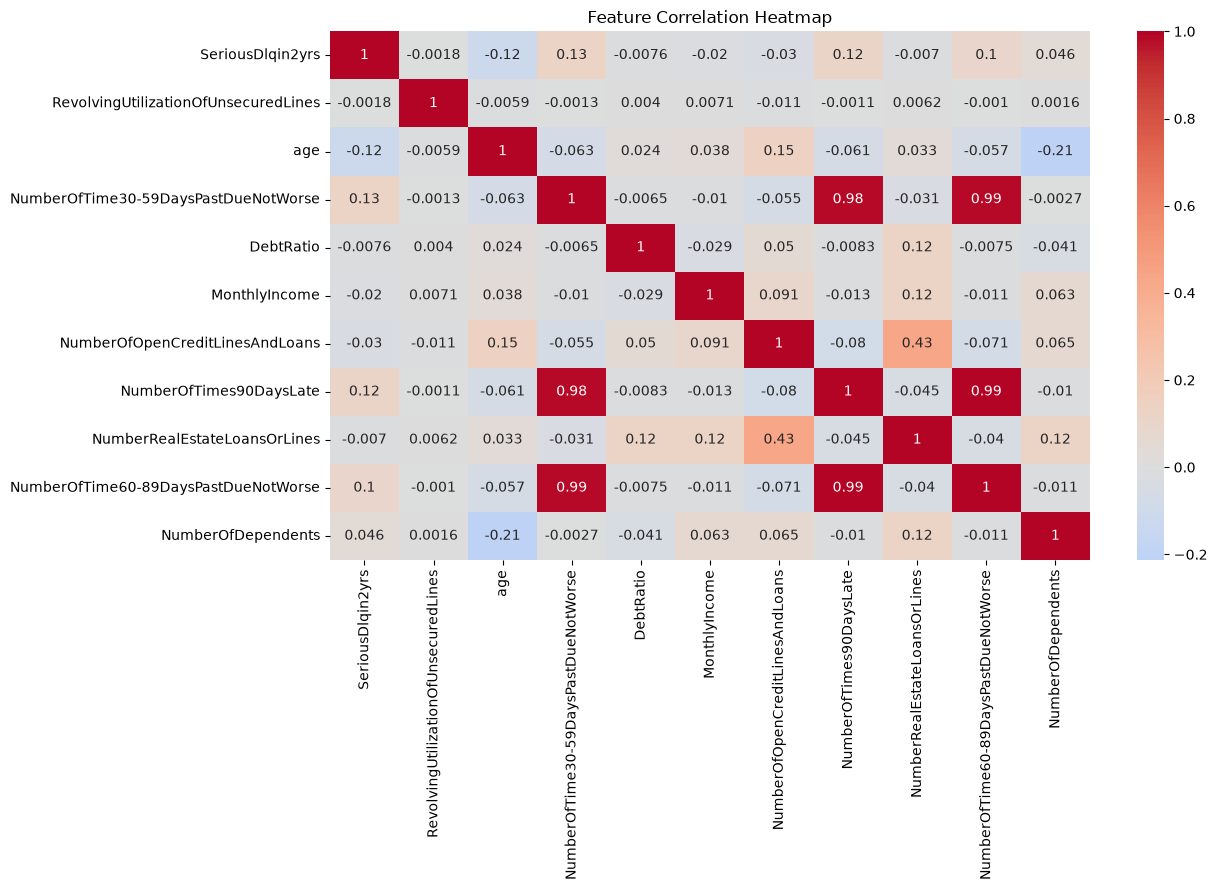

Correlations with target:


,Correlation with target
NumberOfTime30-59DaysPastDueNotWorse,0.125587
NumberOfTimes90DaysLate,0.117175
age,-0.115386
NumberOfTime60-89DaysPastDueNotWorse,0.102261
NumberOfDependents,0.046048
NumberOfOpenCreditLinesAndLoans,-0.029669
MonthlyIncome,-0.019746
DebtRatio,-0.007602
NumberRealEstateLoansOrLines,-0.007038
RevolvingUtilizationOfUnsecuredLines,-0.001802


In [34]:

corr = train.select_dtypes(include=np.number).corr()

plt.figure(figsize=(13, 9))
sns.heatmap(
    corr,
    cmap="coolwarm",
    center=0,
    annot=True,
)
plt.title("Feature Correlation Heatmap")
plt.tight_layout()
plt.show()

print("Correlations with target:")
display(
    corr[target]
    .drop(target)
    .sort_values(key=abs, ascending=False)
    .to_frame("Correlation with target")
)


In [36]:

checks = {
    "Age <= 0": train["age"] <= 0,
    "Negative monthly income": train["MonthlyIncome"] < 0,
    "Negative debt ratio": train["DebtRatio"] < 0,
    "Negative revolving utilization":
        train["RevolvingUtilizationOfUnsecuredLines"] < 0,
    "Utilization above 1":
        train["RevolvingUtilizationOfUnsecuredLines"] > 1,
    "Negative dependents": train["NumberOfDependents"] < 0,
}

for name, condition in checks.items():
    print(f"{name}: {condition.sum()} rows")

print("\nTarget values:")
print(sorted(train[target].dropna().unique()))


Age <= 0: 1 rows
Negative monthly income: 0 rows
Negative debt ratio: 0 rows
Negative revolving utilization: 0 rows
Utilization above 1: 3321 rows
Negative dependents: 0 rows

Target values:
[np.int64(0), np.int64(1)]
